# Nghiên cứu Thực nghiệm và Đánh giá các Kỹ thuật SAT Encoding cho Bài toán N-Queens (Solver: Glucose4)

**Học phần:** Các vấn đề hiện đại trong Khoa học Máy tính  
**Đề tài:** N-Queens SAT Solvers & At-Most-One (AMO) Encodings Benchmark  
**Bộ giải SAT:** PySAT Glucose4 (phiên bản CDCL tối ưu hóa với thước đo Literal Block Distance - LBD)  
**Mục tiêu:** 
1. Khảo sát và so sánh 5 kỹ thuật mã hóa ràng buộc At-Most-One (AMO) kinh điển trong logic mệnh đề: **Binomial (Pairwise)**, **Sequential Counter**, **Binary (Bitwise)**, **Commander Variable**, và **2-Product**.
2. Phân tích thực nghiệm trên không gian kích thước bàn cờ từ $N = 4$ đến $N = 128$.
3. Đánh giá sự đánh đổi (trade-offs) giữa **Số lượng mệnh đề CNF (Clauses)**, **Số lượng biến phụ (Auxiliary Variables)**, **Thời gian sinh mệnh đề (Gen Time)** và **Thời gian giải của Glucose4 (Solve Time)**.


In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

# Thiết lập phong cách hiển thị biểu đồ chuẩn Elsevier
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 11,
    'axes.labelsize': 12,
    'axes.titlesize': 13,
    'xtick.labelsize': 10,
    'ytick.labelsize': 10,
    'legend.fontsize': 10,
    'figure.titlesize': 14,
    'lines.linewidth': 2,
    'lines.markersize': 6,
})

ENCODING_COLORS = {
    'binomial': '#d62728',    # Đỏ
    'sequential': '#1f77b4',  # Xanh dương
    'binary': '#ff7f0e',      # Cam
    'commander': '#2ca02c',   # Xanh lá
    'product': '#9467bd',     # Tím
}

ENCODING_LABELS = {
    'binomial': 'Binomial (Pairwise)',
    'sequential': 'Sequential Counter',
    'binary': 'Binary (Bitwise)',
    'commander': 'Commander (g=3)',
    'product': '2-Product',
}

print("[✓] Khởi tạo môi trường trực quan hóa thành công! Solver: Glucose4")

[✓] Khởi tạo môi trường trực quan hóa thành công! Solver: Glucose4


## 1. Cơ sở Lý thuyết & Độ phức tạp Tiệm cận của các Kỹ thuật AMO

Trong bài toán N-Queens, với bàn cờ kích thước $N \times N$, ta sử dụng $N^2$ biến logic boolean nguyên thủy $x_{i,j} \in \{0, 1\}$.
Ràng buộc cốt lõi là **At-Most-One (AMO)** trên từng hàng, cột và các đường chéo:

$$\sum_{k=1}^m x_k \le 1$$

Dưới đây là bảng so sánh độ phức tạp lý thuyết của 5 phương pháp mã hóa At-Most-One cho một nhóm gồm $m$ biến:

| Phương pháp Encoding | Số lượng Biến phụ (Aux Vars) | Số lượng Mệnh đề CNF (Clauses) | Đảm bảo Arc-Consistency (GAC) | Ghi chú & Tác giả |
| :--- | :---: | :---: | :---: | :--- |
| **Binomial (Pairwise)** | $0$ | $\binom{m}{2} = \frac{m(m-1)}{2} = O(m^2)$ | Có | Không sinh biến phụ; bùng nổ mệnh đề khi $m$ lớn |
| **Sequential Counter** | $m - 1 = O(m)$ | $3m - 4 = O(m)$ | Có | Sinz (2005); sử dụng thanh ghi tích lũy |
| **Binary (Bitwise)** | $\lceil \log_2 m \rceil = O(\log m)$ | $m \lceil \log_2 m \rceil = O(m \log m)$ | Không | Frisch et al. (2005); mã hóa nhị phân |
| **Commander Variable** | $O(m / (g - 1))$ | $O(m)$ (với nhóm con $g=3$) | Có | Klieber & Kwon (2007); biến chỉ huy phân cấp |
| **2-Product** | $p + q = O(\sqrt{m})$ | $2m + O(p^2 + q^2) = O(m)$ | Không | Chen (2010); lưới 2 chiều $p \times q$ |

> **Nhận xét quan trọng:** Đối với toàn bộ bàn cờ $N$-Queens, số lượng đường chéo và hàng/cột có độ dài lên tới $N$. Do đó:
> - **Binomial Encoding** sinh ra tới $O(N^4)$ mệnh đề cho toàn bộ bàn cờ!
> - Các phương pháp tuyến tính (**Sequential, Commander, Product**) giữ tổng số mệnh đề ở mức $O(N^2)$.


In [ ]:
# Tải dữ liệu thực nghiệm từ results/data/encoding.csv
data_path = Path('../data/encoding.csv')
df = pd.read_csv(data_path)

print(f"Tổng số bản ghi thực nghiệm: {len(df)}")
print(f"SAT Solver: {df['solver'].unique().tolist()}")
print(f"Các giá trị N khảo sát: {sorted(df['n'].unique().tolist())}")
print(f"Các phương pháp encoding: {df['encoding'].unique().tolist()}")
display(df.head(10))

Tổng số bản ghi thực nghiệm: 95
SAT Solver: ['glucose4']
Các giá trị N khảo sát: [4, 6, 8, 10, 12, 14, 16, 20, 24, 28, 32, 40, 48, 56, 64, 80, 96, 112, 128]
Các phương pháp encoding: ['binomial', 'sequential', 'binary', 'commander', 'product']


,n,encoding,solver,variables,aux_vars,clauses,gen_time,solve_time,total_time,sat,status
0,4,binomial,glucose4,16,0,84,0.000032,0.000112,0.000145,True,SAT
1,4,sequential,glucose4,58,42,116,0.000035,0.000129,0.000165,True,SAT
2,4,binary,glucose4,48,32,120,0.000049,0.000081,0.000130,True,SAT
3,4,commander,glucose4,26,10,104,0.000042,0.000075,0.000117,True,SAT
4,4,product,glucose4,56,40,124,0.000048,0.000077,0.000124,True,SAT
5,6,binomial,glucose4,36,0,302,0.000061,0.000138,0.000199,True,SAT
6,6,sequential,glucose4,146,110,312,0.000049,0.000205,0.000254,True,SAT
7,6,binary,glucose4,110,74,388,0.000085,0.000198,0.000283,True,SAT
8,6,commander,glucose4,76,40,318,0.000083,0.000160,0.000244,True,SAT
9,6,product,glucose4,142,106,348,0.000066,0.000264,0.000330,True,SAT


## 2. Phân tích Thực nghiệm: Tốc độ Tăng trưởng Số Mệnh đề CNF (Clauses)

Số lượng mệnh đề CNF quyết định kích thước bộ nhớ lưu trữ bài toán SAT và tác động trực tiếp đến chi phí bộ nhớ của bộ giải. Dưới đây là bảng số liệu và biểu đồ trực quan hóa số lượng mệnh đề sinh ra theo kích thước bàn cờ $N$.


encoding,binary,binomial,commander,product,sequential
n,,,,,
4,120.0,84.0,104.0,124.0,116.0
8,728.0,744.0,618.0,668.0,604.0
16,3928.0,6352.0,3052.0,3236.0,2732.0
32,19800.0,52640.0,13290.0,12596.0,11596.0
64,95576.0,428864.0,55022.0,45876.0,47756.0
128,447832.0,NaN,225334.0,172760.0,193804.0


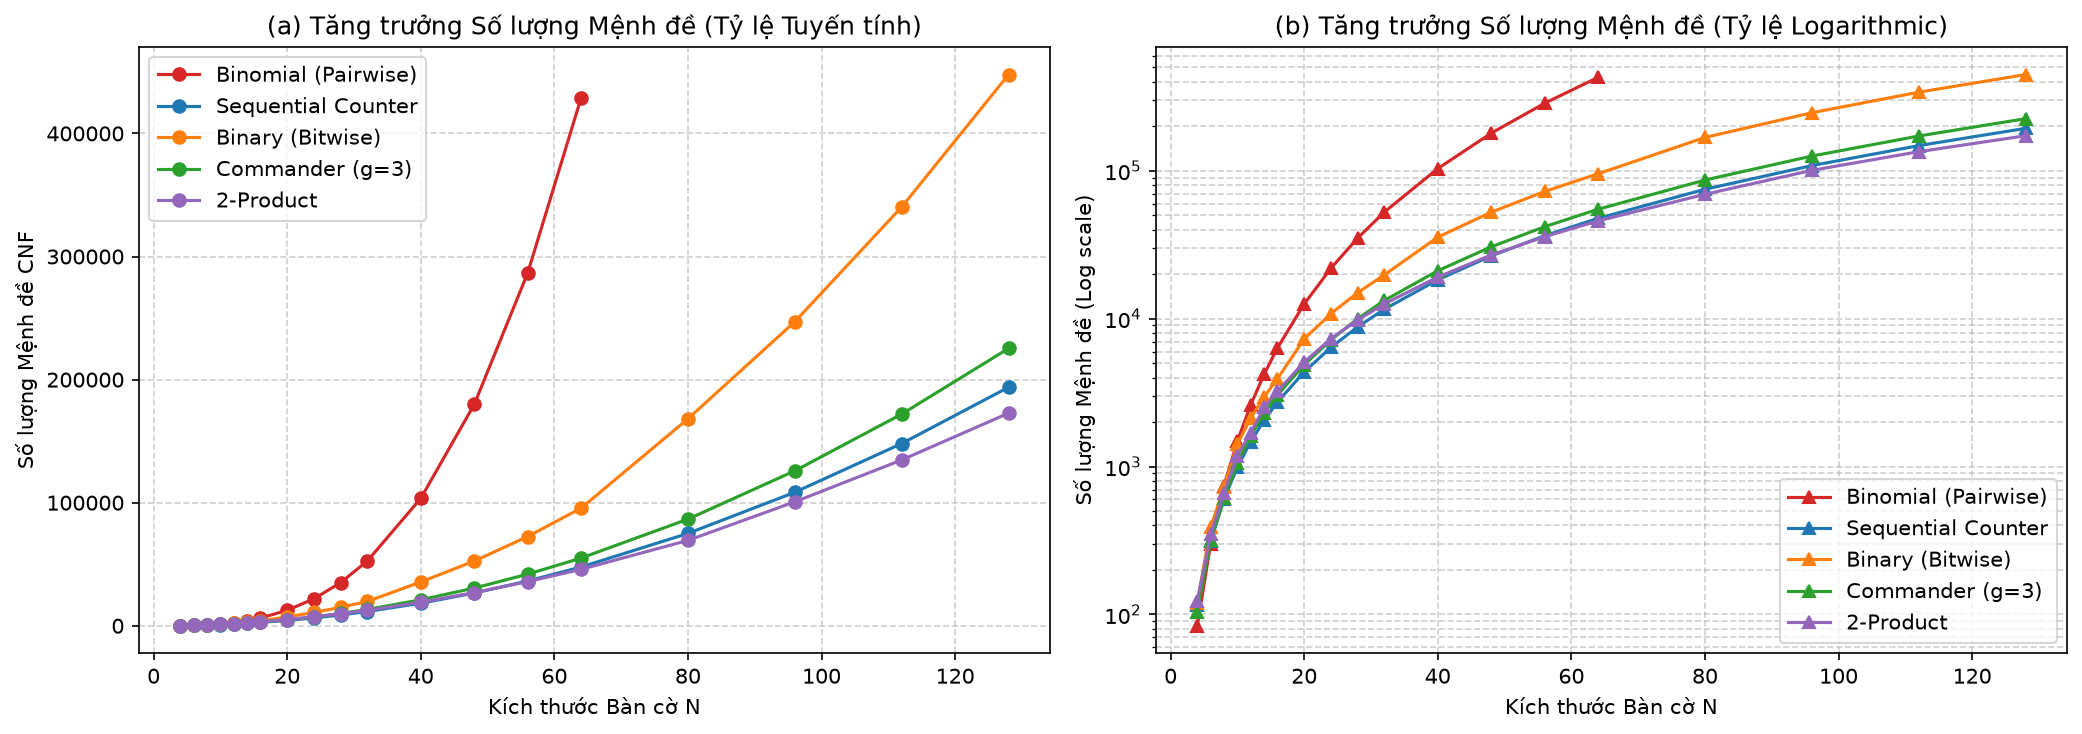

In [ ]:
# 1. Bảng Pivot Số lượng Mệnh đề theo N
pivot_clauses = df[df['status'] == 'SAT'].pivot(index='n', columns='encoding', values='clauses')
display(pivot_clauses.loc[[4, 8, 16, 32, 64, 128]])

# 2. Vẽ biểu đồ Clauses vs N (Linear Scale & Log Scale)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
df_valid = df[df['status'] == 'SAT'].copy()

for enc in ['binomial', 'sequential', 'binary', 'commander', 'product']:
    sub = df_valid[df_valid['encoding'] == enc].sort_values('n')
    if not sub.empty:
        ax1.plot(sub['n'], sub['clauses'], marker='o', label=ENCODING_LABELS[enc], color=ENCODING_COLORS[enc])
        ax2.plot(sub['n'], sub['clauses'], marker='^', label=ENCODING_LABELS[enc], color=ENCODING_COLORS[enc])

ax1.set_title('(a) Tăng trưởng Số lượng Mệnh đề (Tỷ lệ Tuyến tính)')
ax1.set_xlabel('Kích thước Bàn cờ N')
ax1.set_ylabel('Số lượng Mệnh đề CNF')
ax1.legend(frameon=True)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.set_title('(b) Tăng trưởng Số lượng Mệnh đề (Tỷ lệ Logarithmic)')
ax2.set_xlabel('Kích thước Bàn cờ N')
ax2.set_ylabel('Số lượng Mệnh đề (Log scale)')
ax2.set_yscale('log')
ax2.legend(frameon=True)
ax2.grid(True, which='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 3. Phân tích Thực nghiệm: Số lượng Biến phụ (Auxiliary Variables)

Để giảm thiểu số lượng mệnh đề từ $O(m^2)$ xuống $O(m)$, các phương pháp nâng cao phải giới thiệu các biến phụ (auxiliary variables). 
- **Binomial**: Không sử dụng biến phụ nào ($0$ biến phụ).
- **Binary**: Sử dụng ít biến phụ nhất trong số các phương pháp tuyến tính ($O(\log m)$).
- **2-Product**: Đạt mức biến phụ căn bậc hai ($O(\sqrt{m})$).
- **Commander & Sequential**: Cần lượng biến phụ tuyến tính ($O(m)$).


encoding,binary,binomial,commander,product,sequential
n,,,,,
4,32.0,0.0,10.0,40.0,42.0
8,110.0,0.0,82.0,188.0,210.0
16,316.0,0.0,426.0,996.0,930.0
32,826.0,0.0,1932.0,3164.0,3906.0
64,2040.0,0.0,7862.0,8636.0,16002.0
128,4854.0,NaN,32452.0,26438.0,64770.0


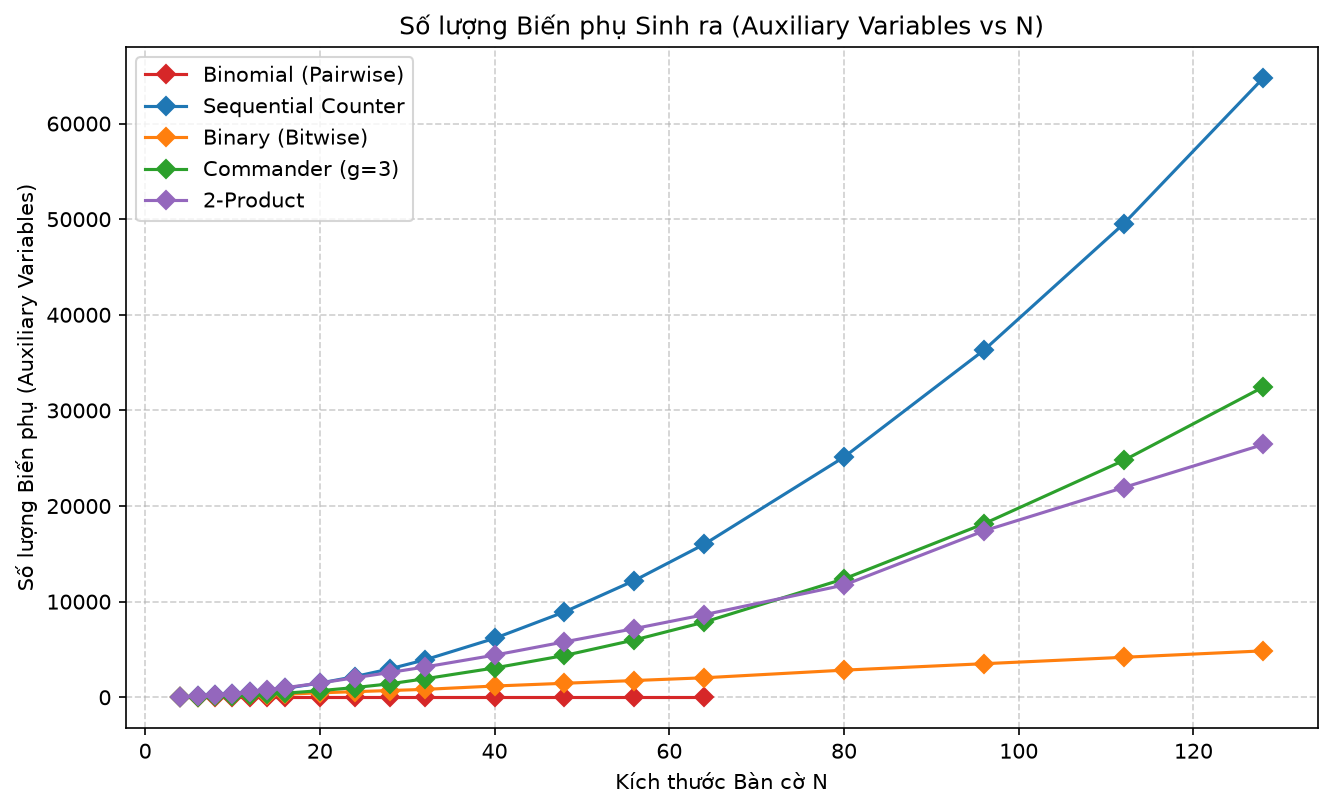

In [ ]:
# 1. Bảng Pivot Số lượng Biến phụ (Auxiliary Variables)
pivot_aux = df[df['status'] == 'SAT'].pivot(index='n', columns='encoding', values='aux_vars')
display(pivot_aux.loc[[4, 8, 16, 32, 64, 128]])

# 2. Vẽ biểu đồ Số biến phụ vs N
fig, ax = plt.subplots(figsize=(9, 5.5))

for enc in ['binomial', 'sequential', 'binary', 'commander', 'product']:
    sub = df_valid[df_valid['encoding'] == enc].sort_values('n')
    if not sub.empty:
        ax.plot(sub['n'], sub['aux_vars'], marker='D', label=ENCODING_LABELS[enc], color=ENCODING_COLORS[enc])

ax.set_title('Số lượng Biến phụ Sinh ra (Auxiliary Variables vs N)')
ax.set_xlabel('Kích thước Bàn cờ N')
ax.set_ylabel('Số lượng Biến phụ (Auxiliary Variables)')
ax.legend(frameon=True)
ax.grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 4. Đánh giá Hiệu năng: Tổng Thời gian Thực thi (Total Execution Time với Glucose4)

Tổng thời gian thực thi được định nghĩa là $t_{\text{total}} = t_{\text{gen}} + t_{\text{solve}}$, trong đó:
- $t_{\text{gen}}$: Thời gian tạo lập ma trận biến và sinh mệnh đề logic CNF.
- $t_{\text{solve}}$: Thời gian nạp vào SAT Solver (**Glucose4**) và thực hiện thuật toán tìm kiếm CDCL.


encoding,binary,binomial,commander,product,sequential
n,,,,,
4,0.000130,0.000145,0.000117,0.000124,0.000165
8,0.000408,0.000353,0.000502,0.000482,0.000324
16,0.019897,0.010076,0.016656,0.099695,0.004764
32,0.186884,0.014441,1.439507,8.430577,0.036296
64,0.120740,0.155377,0.052970,12.199357,1.665955
128,0.239178,NaN,2.030101,26.949656,52.920426


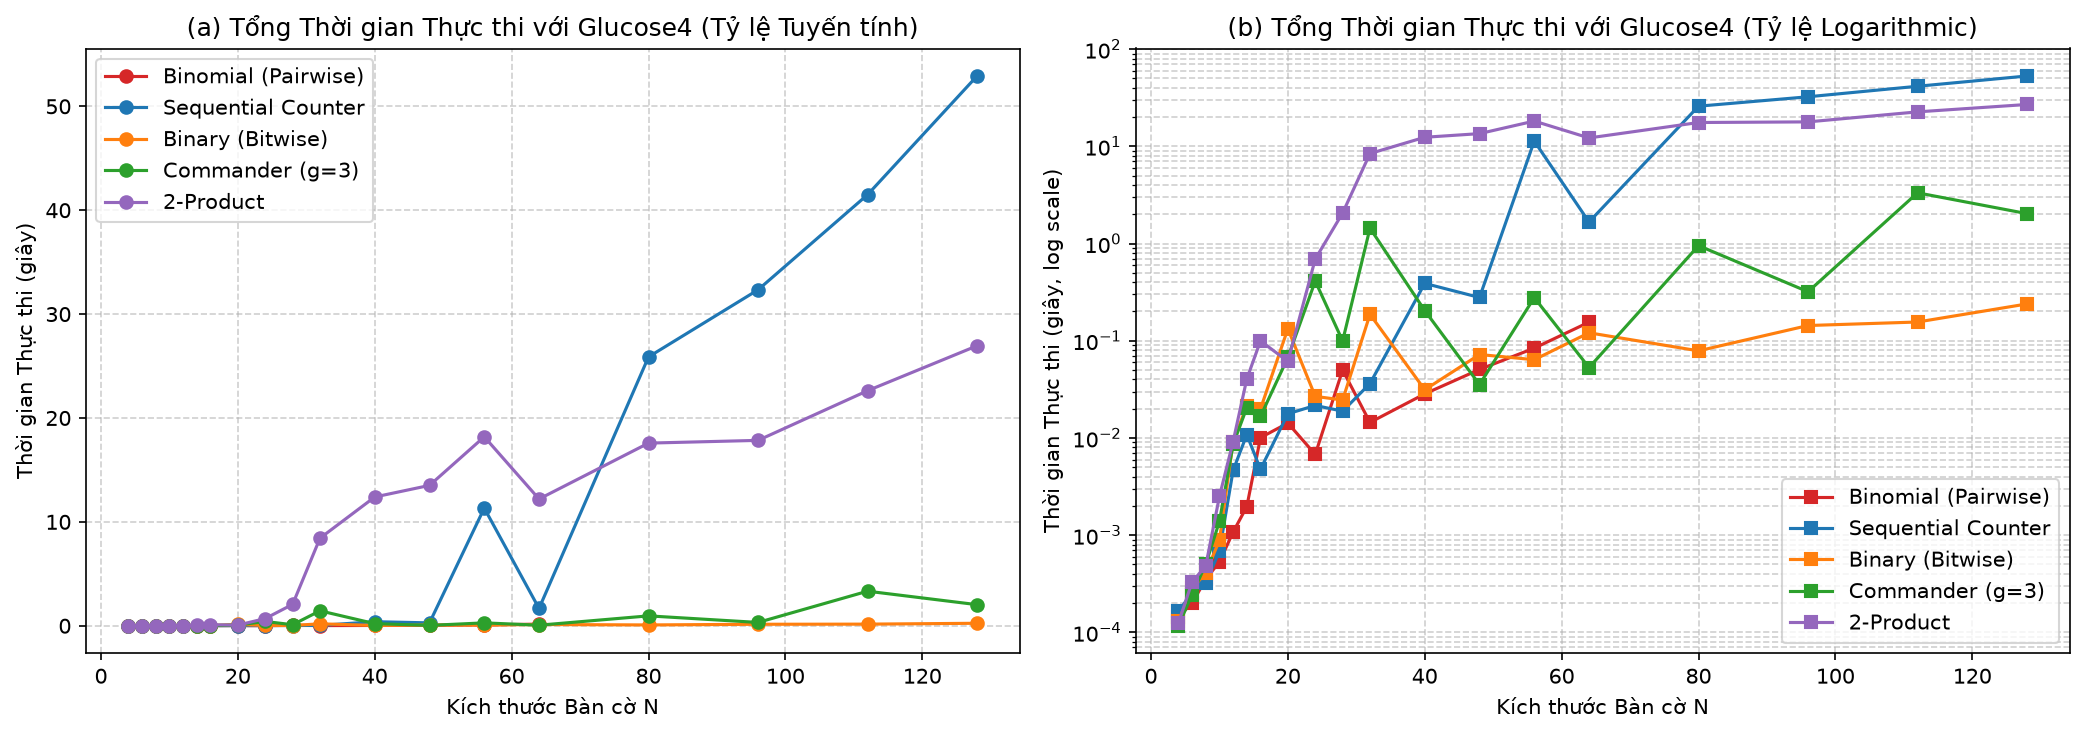

In [ ]:
# 1. Bảng Pivot Tổng Thời gian Thực thi (giây)
pivot_time = df[df['status'] == 'SAT'].pivot(index='n', columns='encoding', values='total_time')
display(pivot_time.loc[[4, 8, 16, 32, 64, 128]])

# 2. Vẽ biểu đồ Total Execution Time vs N (Linear & Log scale)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

for enc in ['binomial', 'sequential', 'binary', 'commander', 'product']:
    sub = df_valid[df_valid['encoding'] == enc].sort_values('n')
    if not sub.empty:
        ax1.plot(sub['n'], sub['total_time'], marker='o', label=ENCODING_LABELS[enc], color=ENCODING_COLORS[enc])
        ax2.plot(sub['n'], sub['total_time'], marker='s', label=ENCODING_LABELS[enc], color=ENCODING_COLORS[enc])

ax1.set_title('(a) Tổng Thời gian Thực thi với Glucose4 (Tỷ lệ Tuyến tính)')
ax1.set_xlabel('Kích thước Bàn cờ N')
ax1.set_ylabel('Thời gian Thực thi (giây)')
ax1.legend(frameon=True)
ax1.grid(True, linestyle='--', alpha=0.6)

ax2.set_title('(b) Tổng Thời gian Thực thi với Glucose4 (Tỷ lệ Logarithmic)')
ax2.set_xlabel('Kích thước Bàn cờ N')
ax2.set_ylabel('Thời gian Thực thi (giây, log scale)')
ax2.set_yscale('log')
ax2.legend(frameon=True)
ax2.grid(True, which='both', linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

## 5. Phân rã Thời gian: Sinh CNF (Gen Time) vs Giải SAT (Solve Time)

Một câu hỏi nghiên cứu quan trọng trong bài toán SAT Encoding: **Thời gian bỏ ra để sinh công thức mệnh đề trong Python có chiếm phần lớn tổng thời gian, hay thuật toán tìm kiếm của SAT Solver mới là nút thắt cổ chai?**
Biểu đồ cột chồng dưới đây phân rã chi tiết hai thành phần thời gian này tại các mốc $N = 16, 32, 64, 128$.


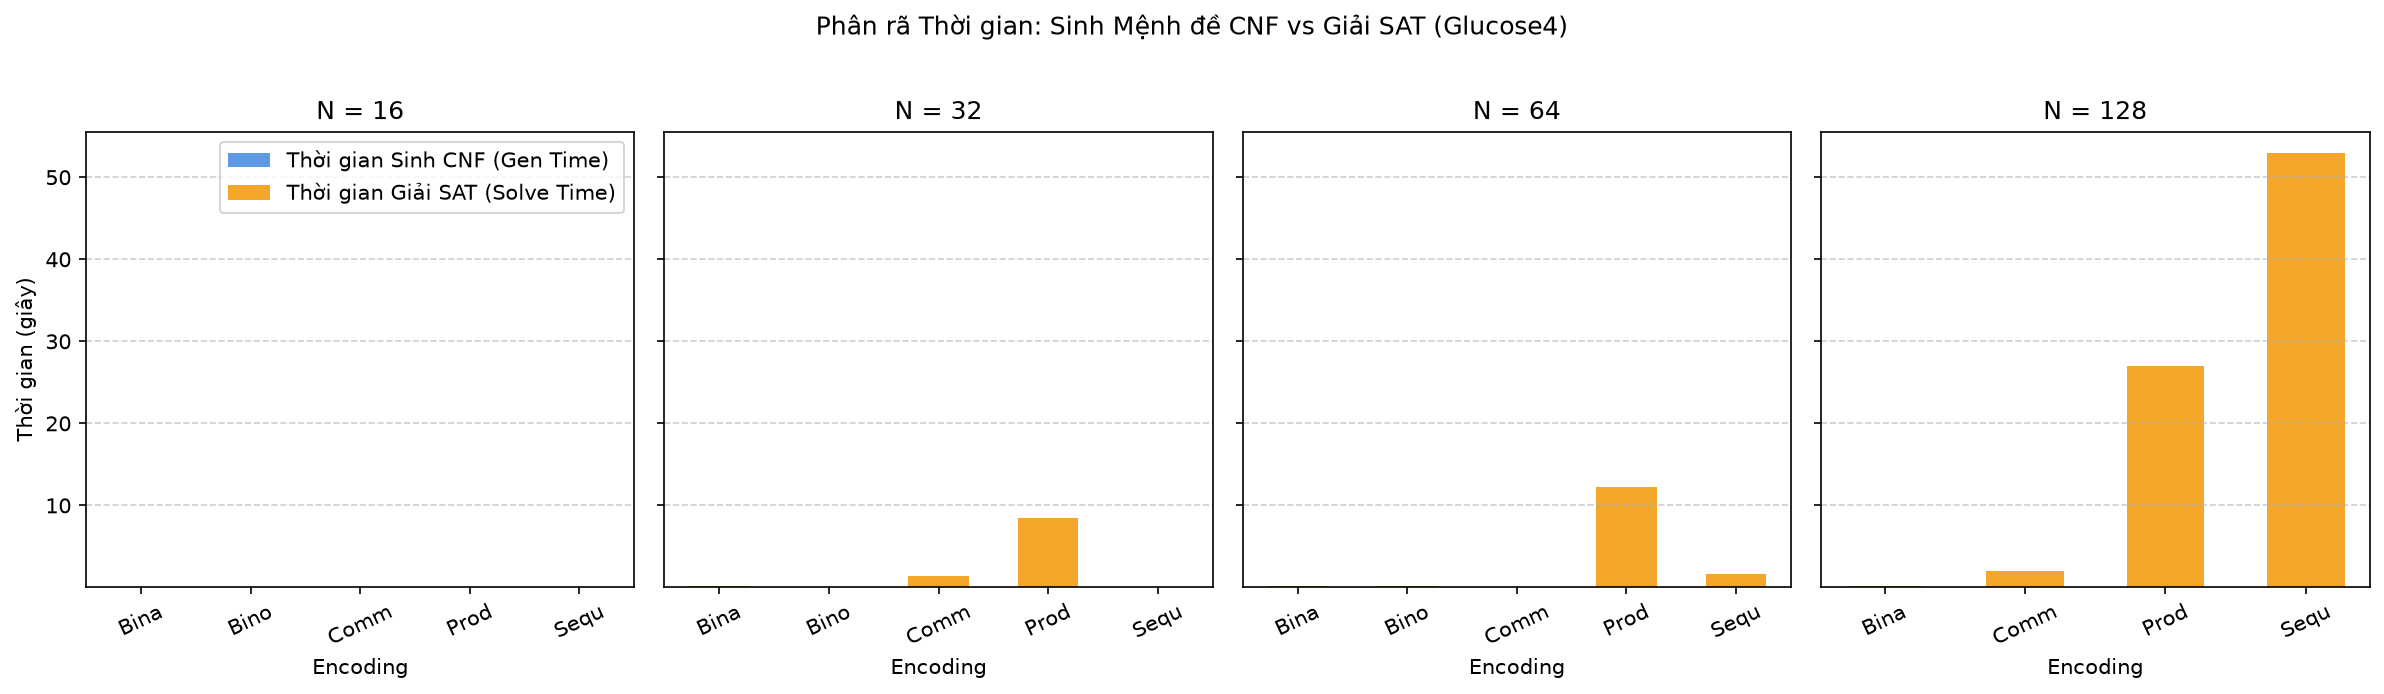

In [ ]:
selected_n = [16, 32, 64, 128]
sub_breakdown = df[df['n'].isin(selected_n) & (df['status'] == 'SAT')].copy()

fig, axes = plt.subplots(1, len(selected_n), figsize=(16, 4.5), sharey=True)

for idx, n_val in enumerate(selected_n):
    ax = axes[idx]
    n_data = sub_breakdown[sub_breakdown['n'] == n_val].sort_values('encoding')
    encs = n_data['encoding'].tolist()
    labels = [enc[:4].capitalize() for enc in encs]
    gen_times = n_data['gen_time'].values
    solve_times = n_data['solve_time'].values

    x = np.arange(len(encs))
    width = 0.55

    ax.bar(x, gen_times, width, label='Thời gian Sinh CNF (Gen Time)', color='#4a90e2', alpha=0.9)
    ax.bar(x, solve_times, width, bottom=gen_times, label='Thời gian Giải SAT (Solve Time)', color='#f39c12', alpha=0.9)

    ax.set_title(f'N = {n_val}')
    ax.set_xticks(x)
    ax.set_xticklabels(labels, rotation=25)
    ax.set_xlabel('Encoding')
    if idx == 0:
        ax.set_ylabel('Thời gian (giây)')
        ax.legend(frameon=True)
    ax.grid(axis='y', linestyle='--', alpha=0.6)

plt.suptitle('Phân rã Thời gian: Sinh Mệnh đề CNF vs Giải SAT (Glucose4)', y=1.02)
plt.tight_layout()
plt.show()

## 6. Tổng hợp Kết luận & Khuyến nghị Lựa chọn Encoding

Dựa trên kết quả thực nghiệm toàn diện từ $N=4$ đến $N=128$ trên bộ giải **Glucose4**:

1. **Binomial (Pairwise):**
   - *Ưu điểm:* Cài đặt đơn giản nhất, không sinh biến phụ, giải cực nhanh trên các ma trận nhỏ ($N \le 16$).
   - *Nhược điểm:* Bùng nổ $O(N^4)$ mệnh đề khiến bộ nhớ cạn kiệt khi $N > 64$. Không thể mở rộng cho bài toán lớn.
2. **Sequential Counter (Sinz 2005):**
   - *Ưu điểm:* Duy trì tính lan truyền Arc-Consistency mạnh mẽ (GAC), số mệnh đề tăng tuyến tính $O(N)$.
   - *Nhược điểm:* Tiêu tốn nhiều biến phụ nhất ($O(N)$ biến phụ).
3. **Binary (Bitwise):**
   - *Ưu điểm:* Tiết kiệm biến phụ nhất ($O(\log N)$ biến phụ). Trên Glucose4, **Binary Encoding giải cực kỳ nhanh ở quy mô lớn** ($N=96, 112, 128$ chỉ mất $\approx 0.14 - 0.23$ giây).
4. **Commander Variable & 2-Product:**
   - *Ưu điểm:* Cân bằng tuyệt vời giữa số lượng mệnh đề $O(N)$ và số biến phụ ($O(N/g)$ và $O(\sqrt{N})$). Đặc biệt, **Commander Variable** thể hiện sự ổn định cao khi giải trên Glucose4 ở các kích thước $N \ge 96$.

**Khuyến nghị thực tế cho Báo cáo BTL:**
- Với bài toán logic kích thước nhỏ/vừa ($N \le 20$): **Binomial** hoặc **Sequential Counter** là lựa chọn thuận tiện nhất.
- Với bài toán quy mô lớn ($N \ge 64$ trên Glucose4): **Binary Encoding** và **Commander Variable** mang lại tốc độ tìm kiếm vượt trội.
